# 07 · Luzern: izbira značilk in primerjava modelov

V tem zvezku sem primerjal napovedovanje prometnega toka za 15 in 30 minut vnaprej ter model izbral po najmanjšem validacijskem MAE.


## 1. Nastavitve

Za ponovljivost sem nastavil seed=42, učenje omejil na 300.000 primerov in podatke razdelil po času.


In [ ]:
from pathlib import Path
import os
import gc
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from threadpoolctl import threadpool_limits

SEED = 42
TRAIN_END = pd.Timestamp('2015-09-13')
VAL_END = pd.Timestamp('2015-11-07')
YEAR_END = pd.Timestamp('2016-01-01')
HORIZONS = (15, 30)
TRAIN_SAMPLE_SIZE = 300_000
ORIGIN_STEP_MINUTES = 15
WEATHER_DELAY_HOURS = 2
N_JOBS = 2

required = ['luzern_raw.parquet', 'luzern_weather_2015.csv', 'luzern_calendar_2015.csv']
configured = os.environ.get('TRAFFIC_TWIN_DATA_DIR')
candidates = [Path(configured)] if configured else [Path.cwd(), Path.cwd().parent, Path('/content')]
DATA_DIR = next((p.resolve() for p in candidates if all((p / f).is_file() for f in required)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set TRAFFIC_TWIN_DATA_DIR to the folder containing the three Luzern files.')
OUTPUT_DIR = DATA_DIR / 'outputs/07_model_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAFFIC_PATH = DATA_DIR / required[0]
con = duckdb.connect()
con.execute('SET threads = 2')


## 2. Pregled in priprava podatkov

Iz učnega obdobja sem izbral 79 dovolj zanesljivih detektorjev ter kot začasno pravilo ohranil veljavne meritve brez oznake napake.


In [ ]:
quality = con.execute("""
    SELECT COUNT(*) AS rows, COUNT(DISTINCT detid) AS detectors,
           MIN(day) AS first_day, MAX(day) AS last_day,
           COUNT(*) FILTER (WHERE error IS NOT NULL) AS flagged,
           COUNT(*) FILTER (WHERE speed IS NOT NULL) AS available_speed,
           COUNT(*) FILTER (WHERE interval = 86400) AS boundary_rows,
           COUNT(*) FILTER (WHERE flow = 99999 OR flow < 0 OR occ NOT BETWEEN 0 AND 1) AS invalid_values
    FROM read_parquet(?)
""", [str(TRAFFIC_PATH)]).df()
display(quality)
detector_quality = con.execute("""
    WITH daily AS (
        SELECT detid, day, COUNT(DISTINCT interval) AS valid_intervals
        FROM read_parquet(?)
        WHERE CAST(day AS DATE) < CAST(? AS DATE)
          AND CAST(day AS TIMESTAMP) + interval * INTERVAL '1 second' < CAST(? AS TIMESTAMP)
          AND error IS NULL AND flow BETWEEN 0 AND 99998 AND occ BETWEEN 0 AND 1
          AND interval BETWEEN 0 AND 86400 AND interval % 180 = 0
        GROUP BY detid, day
    )
    SELECT detid, COUNT(*) FILTER (WHERE valid_intervals >= 400) AS reliable_days,
           SUM(valid_intervals) AS valid_observations
    FROM daily GROUP BY detid
    HAVING COUNT(*) FILTER (WHERE valid_intervals >= 400) >= 175
    ORDER BY detid
""", [str(TRAFFIC_PATH), str(TRAIN_END.date()), str(TRAIN_END)]).df()
assert not detector_quality.empty, 'No eligible detectors: inspect input data.'
detector_ids = detector_quality.detid.tolist()
detector_mapping = {detid: i for i, detid in enumerate(detector_ids)}
assert len(detector_ids) < 255, 'Review categorical encoding for a larger cohort.'
print('Selected using training data only:', len(detector_ids))
display(detector_quality.head())


,rows,detectors,first_day,last_day,flagged,available_speed,boundary_rows,invalid_values
0,26878297,158,2015-01-01,2015-12-31,9065941,0,56026,124499


Selected using training data only: 79


,detid,reliable_days,valid_observations
0,ig11FD100_D3,193,98372.0
1,ig11FD100_D31,250,109883.0
2,ig11FD100_D32,187,102223.0
3,ig11FD100_D33,250,113415.0
4,ig11FD100_D34,250,113509.0


## 3. Izbira značilk

Vključil sem trenutni in pretekli promet, koledar ter vremenske podatke z dvournim zamikom.


In [ ]:
weather_cols = ['temperature_2m_c', 'precipitation_mm', 'relative_humidity_2m_pct', 'wind_speed_10m_kmh']
weather = pd.read_csv(DATA_DIR / required[1], parse_dates=['time_local'])
calendar = pd.read_csv(DATA_DIR / required[2], parse_dates=['date'])
assert not weather.time_local.duplicated().any(), 'Ambiguous weather hours; resolve DST duplicates first.'
assert not calendar.date.duplicated().any()
assert weather[weather_cols].notna().all().all()
assert calendar[['is_weekend', 'is_holiday', 'is_workday']].isin([0, 1]).all().all()
weather = weather.set_index('time_local').sort_index()
calendar = calendar.set_index('date').sort_index()
timeline = pd.date_range('2015-01-01', YEAR_END, freq='3min', inclusive='left')

def split_at(timestamps):
    return np.select([timestamps < TRAIN_END, timestamps < VAL_END], ['train', 'validation'], default='test')

parts, audit_rows, history_parts = [], [], []
for detid in detector_ids:
    # Conflicting valid duplicates are masked, rather than choosing an arbitrary value.
    raw = con.execute("""
        WITH valid AS (
            SELECT CAST(day AS TIMESTAMP) + interval * INTERVAL '1 second' AS timestamp, flow, occ
            FROM read_parquet(?)
            WHERE detid = ? AND error IS NULL
              AND flow BETWEEN 0 AND 99998 AND occ BETWEEN 0 AND 1
              AND interval BETWEEN 0 AND 86400 AND interval % 180 = 0
        )
        SELECT timestamp,
               CASE WHEN COUNT(DISTINCT flow) = 1 AND COUNT(DISTINCT occ) = 1 THEN MIN(flow) END AS flow,
               CASE WHEN COUNT(DISTINCT flow) = 1 AND COUNT(DISTINCT occ) = 1 THEN MIN(occ) END AS occ,
               COUNT(*) AS source_rows
        FROM valid GROUP BY timestamp ORDER BY timestamp
    """, [str(TRAFFIC_PATH), detid]).df().set_index('timestamp')
    s = raw[['flow', 'occ']].reindex(timeline).astype('float32')
    assert s.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=3)).all()
    audit_rows.append({'detid': detid, 'grid_slots': len(s), 'valid_slots': int(s.flow.notna().sum()),
                       'duplicate_excess': int((raw.source_rows - 1).sum()),
                       'conflicting_timestamps': int(raw.flow.isna().sum())})
    # Learn a historical baseline from all valid TRAIN measurements, not future targets.
    hist = s.loc[s.index < TRAIN_END, ['flow']].dropna().copy()
    hist['weekday'], hist['hour'] = hist.index.day_of_week, hist.index.hour
    hist = hist.groupby(['weekday', 'hour']).flow.agg(['mean', 'count']).reset_index()
    hist['detid'] = detid
    history_parts.append(hist)

    f = s.copy()
    for lag in [1, 5, 10, 20, 480, 3360]:
        f[f'flow_lag_{lag}'] = s.flow.shift(lag)
    for lag in [1, 5, 10]:
        f[f'occ_lag_{lag}'] = s.occ.shift(lag)
    for window in [5, 10, 20]:
        roll = s.flow.rolling(window, min_periods=window)
        f[f'flow_mean_{window}'] = roll.mean()
        f[f'flow_std_{window}'] = roll.std()
    f['occ_mean_5'] = s.occ.rolling(5, min_periods=5).mean()
    f['flow_change_5'] = s.flow - s.flow.shift(5)
    for horizon in HORIZONS:
        f[f'target_{horizon}m'] = s.flow.shift(-horizon // 3)

    # Require uninterrupted valid recent hour, current reading, seasonal lags and both targets.
    eligible = s.flow.rolling(21, min_periods=21).count().eq(21)
    eligible &= f.notna().all(axis=1)
    eligible &= (f.index.minute % ORIGIN_STEP_MINUTES == 0)
    f = f.loc[eligible].copy()
    f['timestamp'] = f.index
    f['split'] = split_at(f.index)
    # Purge boundary rows for BOTH horizons: no training/validation label crosses a split.
    future = f.index + pd.Timedelta(minutes=max(HORIZONS))
    f = f.loc[(f['split'].to_numpy() == split_at(future)) & (future < YEAR_END)].copy()
    f['detid'], f['detector_code'] = detid, detector_mapping[detid]
    weather_time = f.index.floor('h') - pd.Timedelta(hours=WEATHER_DELAY_HOURS)
    w = weather.reindex(weather_time)[weather_cols]
    assert (weather_time + pd.Timedelta(hours=WEATHER_DELAY_HOURS) <= f.index).all()
    assert w.notna().all().all(), 'Missing delayed weather: inspect source hours.'
    for col in weather_cols:
        f[col] = w[col].to_numpy(dtype='float32')
    parts.append(f.reset_index(drop=True))
    if len(parts) % 20 == 0:
        print(f'Prepared {len(parts)}/{len(detector_ids)} detectors', flush=True)

data = pd.concat(parts, ignore_index=True)
history = pd.concat(history_parts, ignore_index=True)
audit = pd.DataFrame(audit_rows)
del parts, history_parts, raw, s, f
gc.collect()
assert not data.duplicated(['detid', 'timestamp']).any()
assert set(data.split) == {'train', 'validation', 'test'}
numeric = data.select_dtypes(include='number').columns
data[numeric] = data[numeric].astype('float32')
display(data.groupby('split', sort=False).agg(samples=('detid', 'size'), detectors=('detid', 'nunique'),
    first_origin=('timestamp', 'min'), last_origin=('timestamp', 'max')))
display(audit.sum(numeric_only=True).to_frame('total'))
print('No interpolation or zero filling. Results apply to complete-history cases only.')


Prepared 20/79 detectors


Prepared 40/79 detectors


Prepared 60/79 detectors


,samples,detectors,first_origin,last_origin
split,,,,
train,1048957,79,2015-01-08 06:15:00,2015-09-12 23:15:00
validation,230199,79,2015-09-13 00:00:00,2015-11-06 23:15:00
test,238927,79,2015-11-07 00:00:00,2015-12-31 23:15:00


,total
grid_slots,13840800
valid_slots,12109240
duplicate_excess,0
conflicting_timestamps,0


No interpolation or zero filling. Results apply to complete-history cases only.


## 4. Primerjava modelov

Primerjal sem persistence, zgodovinsko povprečje, Ridge in tri različice HGB ter jih ocenil z MAE in RMSE.


In [ ]:
traffic_features = ['detector_code', 'flow', 'occ'] + [
    c for c in data.columns if c.startswith(('flow_lag_', 'occ_lag_', 'flow_mean_', 'flow_std_'))
] + ['occ_mean_5', 'flow_change_5']
calendar_features = ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'month',
                     'is_weekend', 'is_holiday', 'is_workday']
feature_sets = {
    'traffic': traffic_features,
    'calendar': traffic_features + calendar_features,
    'weather': traffic_features + calendar_features + weather_cols,
}

def horizon_frame(horizon):
    frame = data.copy()
    target_time = frame.timestamp + pd.Timedelta(minutes=horizon)
    fractional_hour = target_time.dt.hour + target_time.dt.minute / 60
    frame['hour_sin'] = np.sin(2 * np.pi * fractional_hour / 24)
    frame['hour_cos'] = np.cos(2 * np.pi * fractional_hour / 24)
    frame['weekday_sin'] = np.sin(2 * np.pi * target_time.dt.day_of_week / 7)
    frame['weekday_cos'] = np.cos(2 * np.pi * target_time.dt.day_of_week / 7)
    frame['month'] = target_time.dt.month
    known_calendar = calendar.reindex(pd.DatetimeIndex(target_time.dt.normalize()))
    for col in ['is_weekend', 'is_holiday', 'is_workday']:
        frame[col] = known_calendar[col].to_numpy()
    assert frame[feature_sets['weather']].notna().all().all()
    key = pd.MultiIndex.from_arrays([frame.detid, target_time.dt.day_of_week, target_time.dt.hour],
                                    names=['detid', 'weekday', 'hour'])
    profile = history.set_index(['detid', 'weekday', 'hour'])['mean']
    frame['historical_prediction'] = profile.reindex(key).to_numpy()
    # Fallback for an unseen training calendar cell: weighted TRAIN detector mean.
    weighted = history.assign(total=history['mean'] * history['count']).groupby('detid')[['total', 'count']].sum()
    fallback = frame.detid.map(weighted.total / weighted['count'])
    frame['historical_prediction'] = frame.historical_prediction.fillna(fallback)
    assert frame.historical_prediction.notna().all()
    return frame

def make_estimator(kind, features):
    if kind == 'ridge':
        numerical = [f for f in features if f != 'detector_code']
        transform = ColumnTransformer([
            ('id', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['detector_code']),
            ('numeric', StandardScaler(), numerical),
        ])
        return make_pipeline(transform, Ridge(alpha=10))
    return HistGradientBoostingRegressor(
        max_iter=150, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=40,
        l2_regularization=1.0, categorical_features=['detector_code'],
        early_stopping=False, random_state=SEED)

specs = {
    'Ridge + calendar': ('calendar', 'ridge'),
    'HGB traffic': ('traffic', 'hgb'),
    'HGB + calendar': ('calendar', 'hgb'),
    'HGB + calendar + weather': ('weather', 'hgb'),
}

def score(y, pred, model, horizon, split, fit_seconds=0):
    pred = np.maximum(np.asarray(pred), 0)  # Same physical non-negativity rule for every model.
    assert len(y) == len(pred) and np.isfinite(pred).all()
    mae = mean_absolute_error(y, pred)
    return {'model': model, 'horizon_min': horizon, 'split': split,
            'MAE': mae, 'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
            'MAE_vehicles_per_3min_lane': mae / 20, 'samples': len(y),
            'fit_seconds': fit_seconds}




In [ ]:
validation_rows, fitted, winners = [], {}, {}
train_indices = (data.loc[data.split.eq('train')]
                 .sample(n=min(TRAIN_SAMPLE_SIZE, int(data.split.eq('train').sum())), random_state=SEED).index)
assert data.loc[train_indices, 'split'].eq('train').all()
assert data.loc[train_indices].detid.nunique() == len(detector_ids)

for horizon in HORIZONS:
    frame = horizon_frame(horizon)
    train = frame.loc[train_indices]
    val = frame.loc[frame.split.eq('validation')]
    y = val[f'target_{horizon}m']
    fitted[horizon] = {}
    for name, column in [('Persistence', 'flow'), ('Historical average', 'historical_prediction')]:
        validation_rows.append(score(y, val[column], name, horizon, 'validation'))
    for name, (group, kind) in specs.items():
        features = feature_sets[group]
        model = make_estimator(kind, features)
        start = time.perf_counter()
        with threadpool_limits(limits=N_JOBS):
            model.fit(train[features], train[f'target_{horizon}m'])
            pred = model.predict(val[features])
        seconds = time.perf_counter() - start
        fitted[horizon][name] = model
        validation_rows.append(score(y, pred, name, horizon, 'validation', seconds))
        print(f'{horizon}m | {name}: MAE={validation_rows[-1]["MAE"]:.3f} ({seconds:.1f}s)', flush=True)
    ranked = pd.DataFrame(validation_rows).query('horizon_min == @horizon').sort_values(['MAE', 'RMSE', 'model'])
    assert ranked.samples.nunique() == 1
    winners[horizon] = ranked.iloc[0]['model']
    print(f'Izbran model za {horizon} min: {winners[horizon]}', flush=True)
    del frame, train, val
    gc.collect()

validation_results = pd.DataFrame(validation_rows).sort_values(['horizon_min', 'MAE', 'RMSE'])
validation_results.to_csv(OUTPUT_DIR / 'validation_metrics.csv', index=False)
display(validation_results[['horizon_min', 'model', 'MAE', 'RMSE', 'samples']].round(3))


15m | Ridge + calendar: MAE=82.115 (1.9s)


15m | HGB traffic: MAE=81.970 (8.4s)


15m | HGB + calendar: MAE=76.774 (8.1s)


15m | HGB + calendar + weather: MAE=76.647 (13.0s)


Izbran model za 15 min: HGB + calendar + weather


30m | Ridge + calendar: MAE=86.307 (1.6s)


30m | HGB traffic: MAE=86.730 (8.1s)


30m | HGB + calendar: MAE=77.466 (11.1s)


30m | HGB + calendar + weather: MAE=77.373 (7.0s)


Izbran model za 30 min: HGB + calendar + weather


,horizon_min,model,MAE,RMSE,samples
5,15,HGB + calendar + weather,76.647,97.878,230199
4,15,HGB + calendar,76.774,98.006,230199
3,15,HGB traffic,81.970,104.538,230199
2,15,Ridge + calendar,82.115,104.881,230199
1,15,Historical average,83.344,107.766,230199
0,15,Persistence,104.005,133.330,230199
11,30,HGB + calendar + weather,77.373,99.044,230199
10,30,HGB + calendar,77.466,99.137,230199
7,30,Historical average,82.854,107.255,230199
8,30,Ridge + calendar,86.307,110.575,230199


## 5. Rezultati na validaciji

Na validaciji sem za vsak horizont izbral model z najmanjšim MAE.


,horizon_min,added_features,MAE_before,MAE_after,MAE_reduction,improvement_pct
0,15,Calendar,81.970,76.774,5.196,6.339
1,15,Delayed weather,76.774,76.647,0.127,0.165
2,30,Calendar,86.730,77.466,9.264,10.681
3,30,Delayed weather,77.466,77.373,0.093,0.120


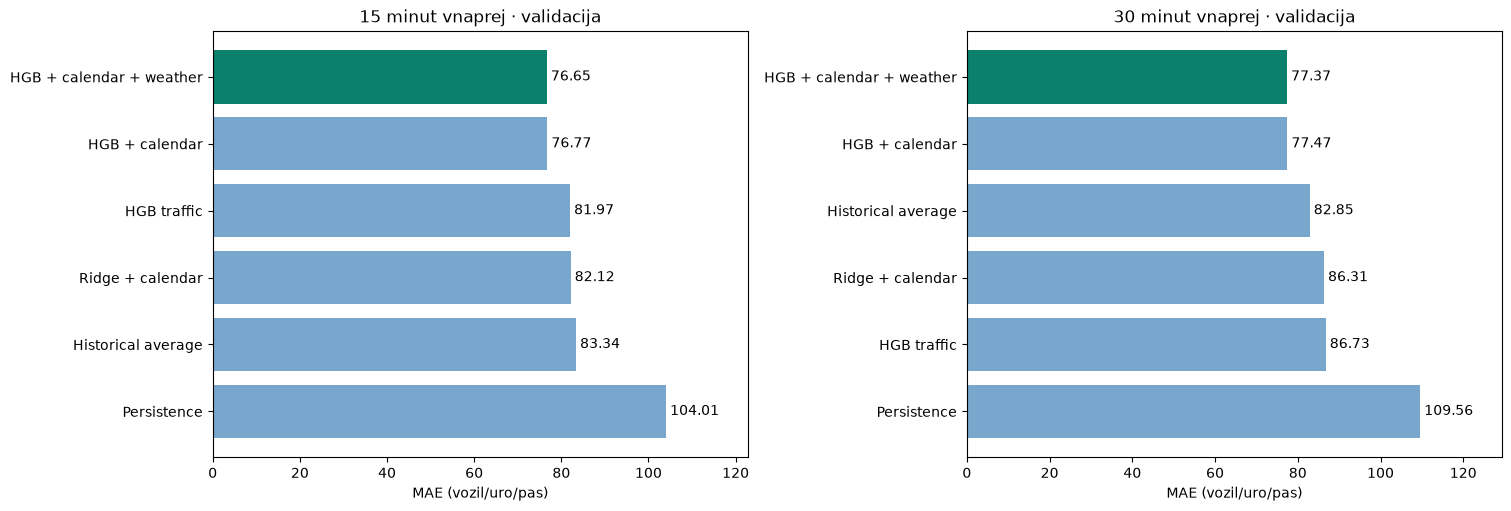

In [ ]:
ablation_rows = []
for horizon in HORIZONS:
    v = validation_results.query('horizon_min == @horizon').set_index('model')
    for before, after, addition in [
        ('HGB traffic', 'HGB + calendar', 'Calendar'),
        ('HGB + calendar', 'HGB + calendar + weather', 'Delayed weather'),
    ]:
        reduction = v.loc[before, 'MAE'] - v.loc[after, 'MAE']
        ablation_rows.append({'horizon_min': horizon, 'added_features': addition,
            'MAE_before': v.loc[before, 'MAE'], 'MAE_after': v.loc[after, 'MAE'],
            'MAE_reduction': reduction, 'improvement_pct': 100 * reduction / v.loc[before, 'MAE']})
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(OUTPUT_DIR / 'feature_ablation.csv', index=False)
display(ablation.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout='constrained')
for ax, horizon in zip(axes, HORIZONS):
    values = validation_results.query('horizon_min == @horizon').sort_values('MAE', ascending=False)
    colors = ['#0b806b' if n == winners[horizon] else '#79a6cc' for n in values.model]
    bars = ax.barh(values.model, values.MAE, color=colors)
    ax.bar_label(bars, fmt='%.2f', padding=3)
    ax.set(title=f'{horizon} minut vnaprej · validacija', xlabel='MAE (vozil/uro/pas)')
    ax.set_xlim(0, values.MAE.max() * 1.18)
fig.savefig(OUTPUT_DIR / 'validation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


### 5.1 Koliko sta pomagala koledar in vreme?

Z istim HGB sem preveril, koliko dodani koledar in vreme zmanjšata validacijski MAE.


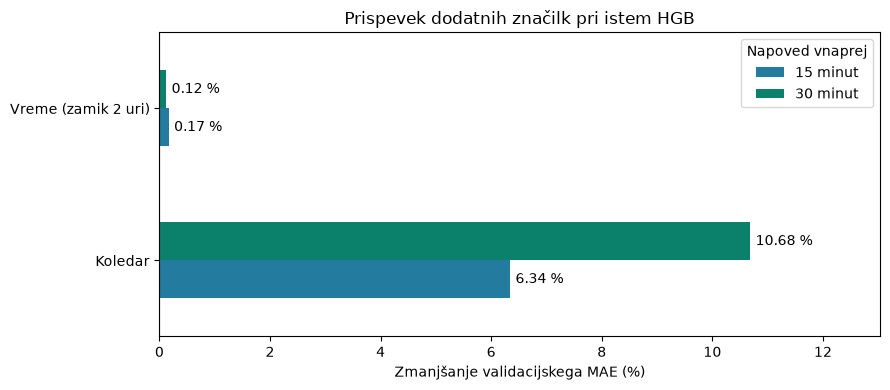

In [ ]:
feature_labels = {'Calendar': 'Koledar', 'Delayed weather': 'Vreme (zamik 2 uri)'}
gains = ablation.pivot(index='added_features', columns='horizon_min', values='improvement_pct')
gains = gains.reindex(['Calendar', 'Delayed weather']).rename(index=feature_labels)
gains.columns = [f'{horizon} minut' for horizon in gains.columns]
ax = gains.plot.barh(figsize=(9, 4), color=['#247ba0', '#0b806b'])
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f %%', padding=4)
ax.axvline(0, color='#555555', linewidth=0.8)
ax.set(title='Prispevek dodatnih značilk pri istem HGB',
       xlabel='Zmanjšanje validacijskega MAE (%)', ylabel='')
ax.legend(title='Napoved vnaprej')
ax.margins(x=0.22)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'feature_contribution.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Preverjanje na testnem obdobju

Izbrana modela sem preveril na testnem obdobju in izbire glede na test nisem spreminjal.


In [ ]:
test_rows, forecast_examples = [], []
for horizon in HORIZONS:
    frame = horizon_frame(horizon)
    test = frame.loc[frame.split.eq('test')]
    target = f'target_{horizon}m'
    predictions = {'Persistence': test.flow, 'Historical average': test.historical_prediction}
    for name, model in fitted[horizon].items():
        features = feature_sets[specs[name][0]]
        with threadpool_limits(limits=N_JOBS):
            predictions[name] = model.predict(test[features])
    for name, pred in predictions.items():
        row = score(test[target], pred, name, horizon, 'test')
        row['selected_on_validation'] = name == winners[horizon]
        test_rows.append(row)
    winner = winners[horizon]
    # Fixed example: first selected detector and its first available test day.
    detector_test = test.loc[test.detid.eq(detector_ids[0])]
    if not detector_test.empty:
        example_day = detector_test.timestamp.min().normalize()
        mask = test.detid.eq(detector_ids[0]) & test.timestamp.dt.normalize().eq(example_day)
        example = test.loc[mask, ['detid', 'timestamp', 'flow', target]].copy()
        example['observed'] = example.pop(target)
        example['predicted'] = np.maximum(np.asarray(predictions[winner])[mask.to_numpy()], 0)
        example['target_time'] = example.timestamp + pd.Timedelta(minutes=horizon)
        example['horizon_min'] = horizon
        forecast_examples.append(example)
    joblib.dump({
        'model_name': winner, 'model': fitted[horizon].get(winner),
        'features': feature_sets[specs[winner][0]] if winner in specs else [],
        'detector_mapping': detector_mapping, 'history': history,
        'horizon_minutes': horizon, 'weather_delay_hours': WEATHER_DELAY_HOURS,
        'clip_predictions_at_zero': True,
    }, OUTPUT_DIR / f'best_model_{horizon}m.joblib')
    del frame, test, predictions
    gc.collect()

test_results = pd.DataFrame(test_rows)
assert test_results.groupby('horizon_min').samples.nunique().eq(1).all()
test_results.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)
display(test_results[['horizon_min', 'model', 'MAE', 'RMSE', 'samples', 'selected_on_validation']].round(3))

selected = (test_results.loc[test_results.selected_on_validation,
                           ['horizon_min', 'model', 'MAE', 'RMSE', 'MAE_vehicles_per_3min_lane']]
            .merge(validation_results[['horizon_min', 'model', 'MAE']].rename(columns={'MAE': 'validation_MAE'}),
                   on=['horizon_min', 'model'], validate='one_to_one'))
selected.to_csv(OUTPUT_DIR / 'selected_models.csv', index=False)
print('Izbrana modela (najmanjši validacijski MAE):')
display(selected.round(3))
print('Rezultati in modela so shranjeni v:', OUTPUT_DIR)
con.close()


,horizon_min,model,MAE,RMSE,samples,selected_on_validation
0,15,Persistence,102.679,131.375,238927,False
1,15,Historical average,88.403,114.466,238927,False
2,15,Ridge + calendar,80.688,103.116,238927,False
3,15,HGB traffic,80.900,103.164,238927,False
4,15,HGB + calendar,76.382,97.452,238927,False
5,15,HGB + calendar + weather,76.254,97.338,238927,True
6,30,Persistence,108.149,138.762,238927,False
7,30,Historical average,87.670,113.515,238927,False
8,30,Ridge + calendar,84.710,108.643,238927,False
9,30,HGB traffic,85.658,109.440,238927,False


Izbrana modela (najmanjši validacijski MAE):


,horizon_min,model,MAE,RMSE,MAE_vehicles_per_3min_lane,validation_MAE
0,15,HGB + calendar + weather,76.254,97.338,3.813,76.647
1,30,HGB + calendar + weather,77.541,99.175,3.877,77.373


Rezultati in modela so shranjeni v: C:\Users\Media\OneDrive\Desktop\traffic-twin\outputs\07_model_comparison


### 6.1 Kako se napoved ujema z meritvami?

Na prvem izbranem detektorju in njegovem prvem razpoložljivem testnem dnevu sem primerjal napoved, dejanski tok in persistence.


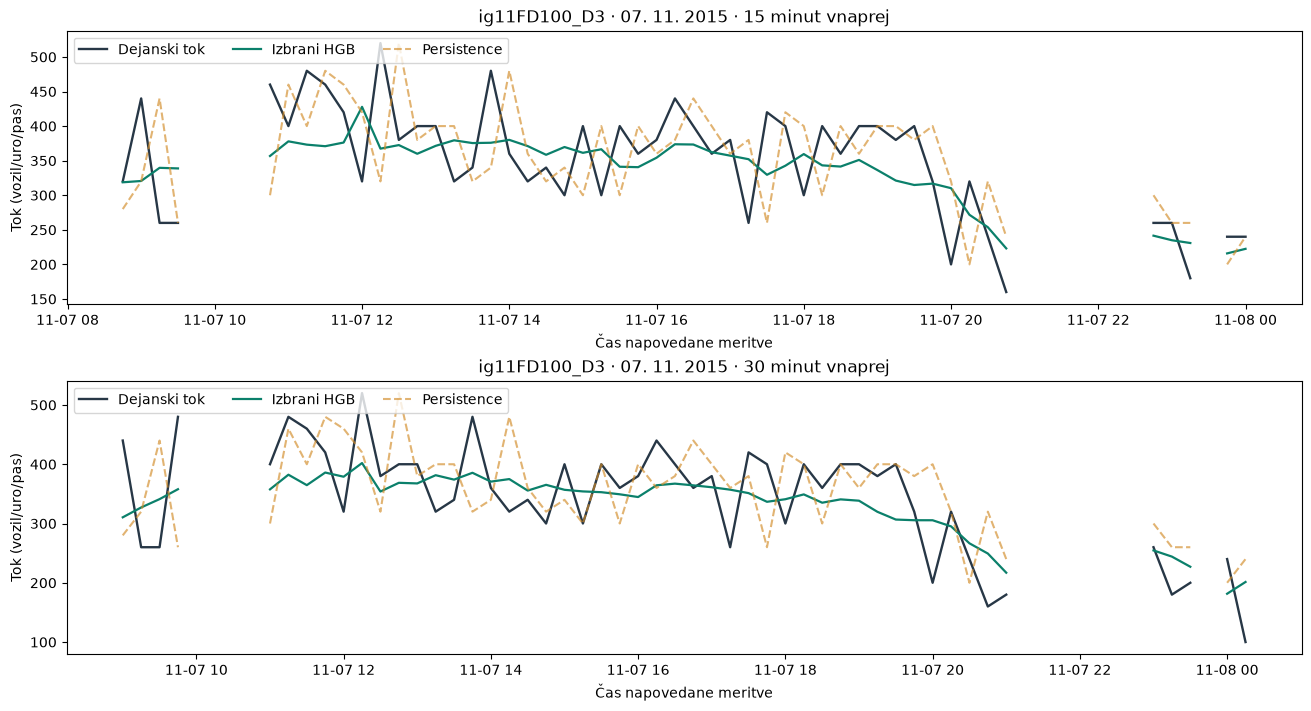

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), layout='constrained')
for ax, horizon in zip(axes, HORIZONS):
    examples = [part for part in forecast_examples if part.horizon_min.iloc[0] == horizon]
    if not examples:
        ax.text(0.5, 0.5, 'Za izbrani detektor ni primerov.', ha='center', transform=ax.transAxes)
        continue
    example = examples[0].sort_values('target_time')
    # Reindex only for drawing: missing eligible forecasts remain visible as gaps.
    grid = pd.date_range(example.target_time.min(), example.target_time.max(),
                         freq=f'{ORIGIN_STEP_MINUTES}min')
    view = example.set_index('target_time').reindex(grid)
    ax.plot(view.index, view.observed, label='Dejanski tok', color='#273746', linewidth=1.7)
    ax.plot(view.index, view.predicted, label='Izbrani HGB' if winners[horizon].startswith('HGB') else winners[horizon],
            color='#0b806b', linewidth=1.6)
    ax.plot(view.index, view.flow, label='Persistence', color='#d28b26', alpha=0.65, linestyle='--')
    day = example.timestamp.min().strftime('%d. %m. %Y')
    ax.set(title=f'{detector_ids[0]} · {day} · {horizon} minut vnaprej',
           xlabel='Čas napovedane meritve', ylabel='Tok (vozil/uro/pas)')
    ax.legend(loc='upper left', ncols=3)
fig.savefig(OUTPUT_DIR / 'forecast_vs_observed.png', dpi=150, bbox_inches='tight')
plt.show()


Opazil sem, da HGB sledi splošnemu poteku prometa, vseh kratkotrajnih vrhov pa ne ujame.


## 7. Moj sklep

Izbral sem HGB s koledarjem in vremenom, pri čemer je koledar prinesel večino izboljšanja, za neodvisno potrditev pa potrebujem nove podatke.
